# Overview of Argoverse 2 dataset

In [1]:
from collections import Counter
from pathlib import Path
import os

from tqdm import tqdm
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd

### Dataset Statistics
Agent type distribution in the AV2 motion forecasting data.
The five tracked types are `vehicle`, `pedestrian`, `motorcyclist`, `cyclist`, and `bus`.
The `other` bucket covers the remaining AV2 object types: `static`, `background`, `construction`, `riderless_bicycle`, and `unknown` — these appear as non-focal agents only.

100%|██████████| 24984/24984 [01:37<00:00, 257.52it/s]


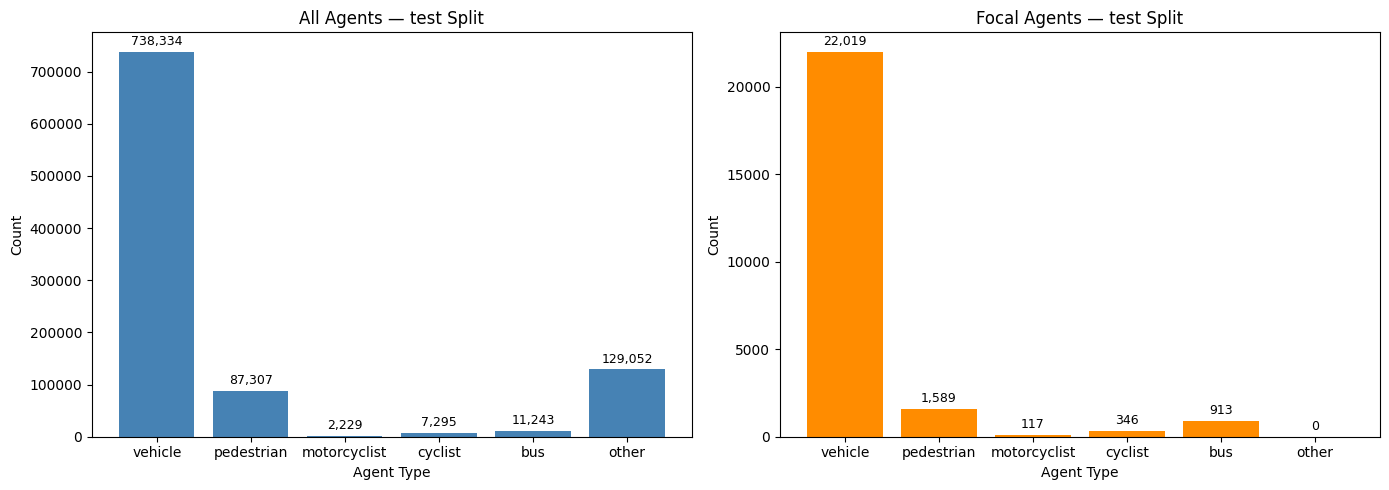

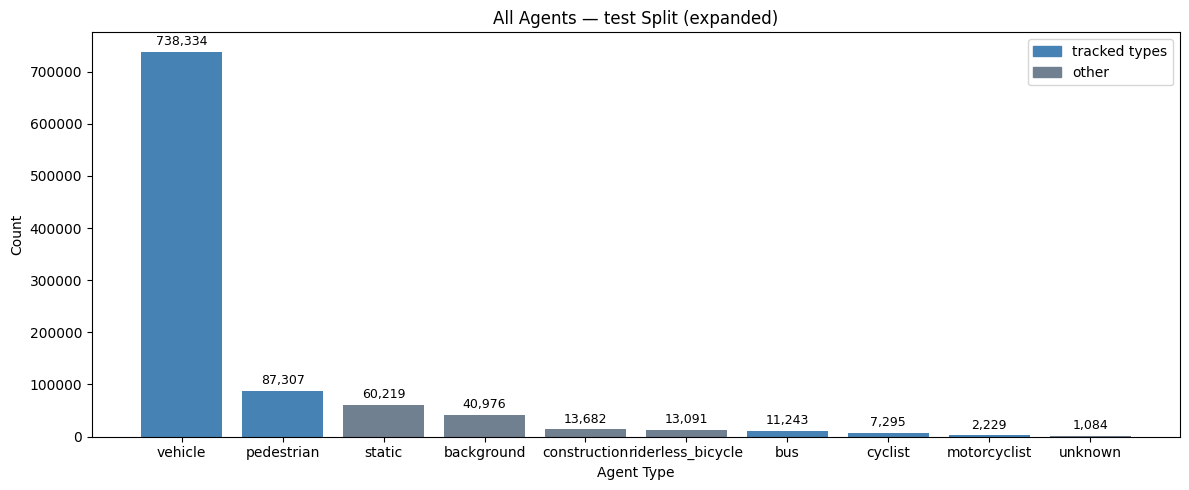

All agents:   {'vehicle': 738334, 'pedestrian': 87307, 'motorcyclist': 2229, 'cyclist': 7295, 'bus': 11243, 'other': 129052}
Focal agents: {'vehicle': 22019, 'pedestrian': 1589, 'motorcyclist': 117, 'cyclist': 346, 'bus': 913, 'other': 0}
'Other' breakdown: {'static': 60219, 'background': 40976, 'construction': 13682, 'riderless_bicycle': 13091, 'unknown': 1084}


In [2]:
data_root = Path("../data")
split = "test"
split_dir = data_root / "av2" / split
AGENT_TYPES = ["vehicle", "pedestrian", "motorcyclist", "cyclist", "bus"]

type_counts = Counter()
focal_type_counts = Counter()

for s_id in tqdm(sorted(os.listdir(split_dir))):
    df = pd.read_parquet(split_dir / s_id / f"scenario_{s_id}.parquet")
    type_counts.update(df.groupby("track_id")["object_type"].first().tolist())
    focal_id = df["focal_track_id"].iloc[0]
    focal_type = df[df["track_id"] == focal_id]["object_type"].iloc[0]
    focal_type_counts[focal_type] += 1

all_counts = {t: type_counts.get(t, 0) for t in AGENT_TYPES}
all_counts["other"] = sum(v for k, v in type_counts.items() if k not in AGENT_TYPES)
focal_counts = {t: focal_type_counts.get(t, 0) for t in AGENT_TYPES}
focal_counts["other"] = sum(v for k, v in focal_type_counts.items() if k not in AGENT_TYPES)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, counts, title, color in [
    (axes[0], all_counts,   f"All Agents — {split} Split",   "steelblue"),
    (axes[1], focal_counts, f"Focal Agents — {split} Split", "darkorange"),
]:
    bars = ax.bar(counts.keys(), counts.values(), color=color)
    ax.set_title(title)
    ax.set_xlabel("Agent Type")
    ax.set_ylabel("Count")
    top = max(counts.values())
    for bar, v in zip(bars, counts.values()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + top * 0.01,
                f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

# All agent types with "other" expanded into individual subtypes, sorted by count
expanded_counts = dict(sorted(type_counts.items(), key=lambda x: -x[1]))
bar_colors = ["steelblue" if k in AGENT_TYPES else "slategray" for k in expanded_counts]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(expanded_counts.keys(), expanded_counts.values(), color=bar_colors)
ax.set_title(f"All Agents — {split} Split (expanded)")
ax.set_xlabel("Agent Type")
ax.set_ylabel("Count")
top = max(expanded_counts.values())
for bar, v in zip(bars, expanded_counts.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + top * 0.01,
            f"{v:,}", ha="center", va="bottom", fontsize=9)

ax.legend(handles=[Patch(color="steelblue", label="tracked types"), Patch(color="slategray", label="other")])
plt.tight_layout()
plt.show()

print("All agents:  ", dict(all_counts))
print("Focal agents:", dict(focal_counts))
print("'Other' breakdown:", dict(sorted({k: v for k, v in type_counts.items() if k not in AGENT_TYPES}.items(), key=lambda x: -x[1])))